In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

data_path = Path("../data/Online Retail.xlsx")

df = pd.read_excel(data_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
df.describe()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Statistical Summary:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [3]:
print("Negative Quantity:", (df["Quantity"] < 0).sum())

print("Zero Quantity:", (df["Quantity"] == 0).sum())

print("Negative UnitPrice:", (df["UnitPrice"] < 0).sum())

print("Zero UnitPrice:", (df["UnitPrice"] == 0).sum())

print("Cancellation Invoices:", df["InvoiceNo"].astype(str).str.startswith("C").sum())

print("Missing Customer IDs:", df["CustomerID"].isnull().sum())

Negative Quantity: 10624
Zero Quantity: 0
Negative UnitPrice: 2
Zero UnitPrice: 2515
Cancellation Invoices: 9288
Missing Customer IDs: 135080


In [4]:
df_clean = df.copy()

# Remove cancelled invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Remove missing customer IDs
df_clean = df_clean.dropna(subset=["CustomerID"])

# Keep only positive quantities and prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

# Calculate total transaction value
df_clean["TotalAmount"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("Original Dataset:", df.shape)
print("Cleaned Dataset:", df_clean.shape)
print("Missing Customer IDs:", df_clean["CustomerID"].isnull().sum())
print("Negative Quantities:", (df_clean["Quantity"] < 0).sum())
print("Non-positive Prices:", (df_clean["UnitPrice"] <= 0).sum())

Original Dataset: (541909, 8)
Cleaned Dataset: (397884, 9)
Missing Customer IDs: 0
Negative Quantities: 0
Non-positive Prices: 0


In [5]:
print("First Transaction:", df_clean["InvoiceDate"].min())
print("Last Transaction:", df_clean["InvoiceDate"].max())
print("Unique Customers:", df_clean["CustomerID"].nunique())
print("Unique Invoices:", df_clean["InvoiceNo"].nunique())

First Transaction: 2010-12-01 08:26:00
Last Transaction: 2011-12-09 12:50:00
Unique Customers: 4338
Unique Invoices: 18532


In [6]:
import datetime as dt

reference_date = df_clean["InvoiceDate"].max() + dt.timedelta(days=1)

rfm = df_clean.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
})

rfm.rename(columns={
    "InvoiceDate": "Recency",
    "InvoiceNo": "Frequency",
    "TotalAmount": "Monetary"
}, inplace=True)

rfm.head()

C:\Users\admin\AppData\Local\Temp\ipykernel_24132\1557070785.py:11: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  rfm.rename(columns={


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


RFM Summary:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


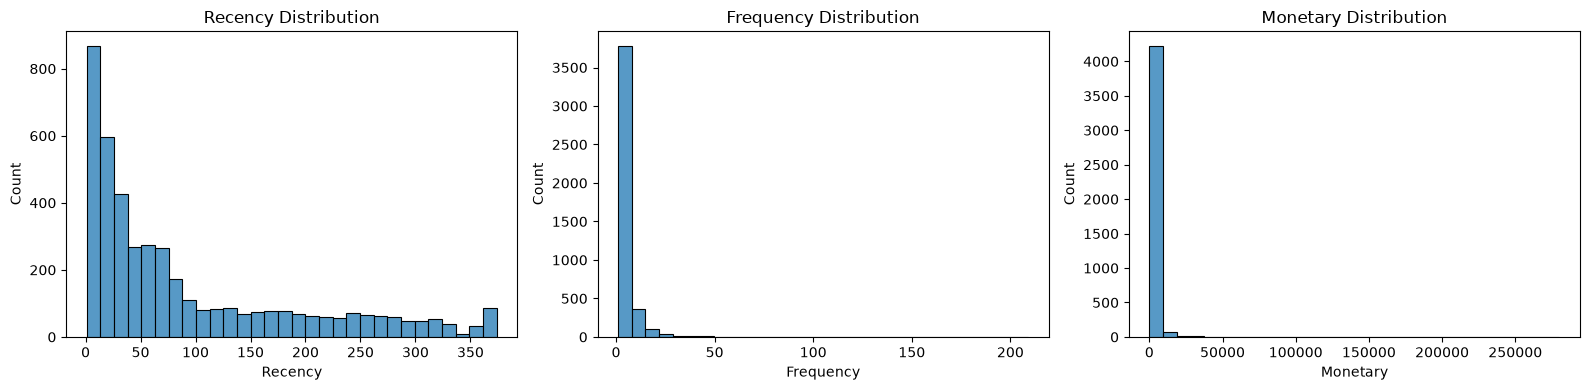

In [7]:
print("RFM Summary:")
display(rfm.describe())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(rfm["Recency"], bins=30, ax=axes[0])
axes[0].set_title("Recency Distribution")

sns.histplot(rfm["Frequency"], bins=30, ax=axes[1])
axes[1].set_title("Frequency Distribution")

sns.histplot(rfm["Monetary"], bins=30, ax=axes[2])
axes[2].set_title("Monetary Distribution")

plt.tight_layout()
plt.show()

In [10]:
from sklearn.preprocessing import StandardScaler

rfm_log = rfm.copy()

rfm_log["Recency"] = np.log1p(rfm_log["Recency"])
rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])
rfm_log["Monetary"] = np.log1p(rfm_log["Monetary"])

print("Skewness before transformation:")
print(rfm.skew())

print("\nSkewness after transformation:")
print(rfm_log.skew())

Skewness before transformation:
Recency       1.246048
Frequency    12.067031
Monetary     19.324953
dtype: float64

Skewness after transformation:
Recency     -0.379169
Frequency    1.208652
Monetary     0.393553
dtype: float64


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

print("Scaled RFM Summary:")
display(rfm_scaled.describe().round(2))

Scaled RFM Summary:


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-2.34,-0.96,-4.00
25%,-0.66,-0.96,-0.69
50%,0.09,-0.36,-0.06
75%,0.84,0.65,0.65
max,1.56,5.86,4.73


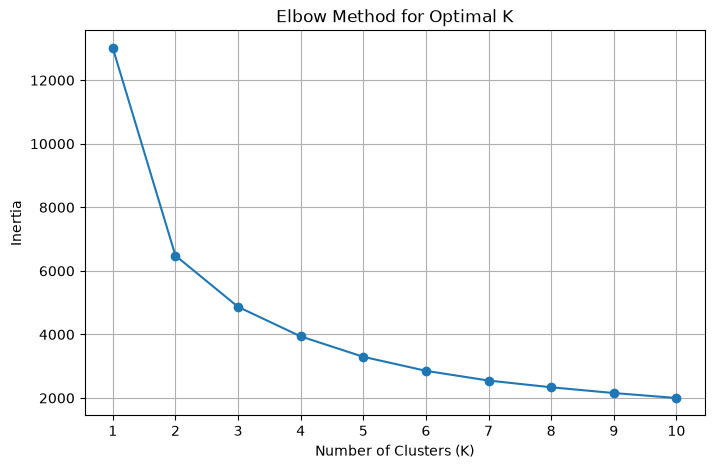

In [12]:
from sklearn.cluster import KMeans

inertia = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [13]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.4257
K = 3, Silhouette Score = 0.3286
K = 4, Silhouette Score = 0.3326
K = 5, Silhouette Score = 0.3177
K = 6, Silhouette Score = 0.3161


In [14]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print("Customer Distribution:")
print(rfm["Cluster"].value_counts())

print("\nCluster Percentages:")
print(
    (rfm["Cluster"].value_counts(normalize=True) * 100).round(2)
)

Customer Distribution:
Cluster
0    2671
1    1667
Name: count, dtype: int64

Cluster Percentages:
Cluster
0    61.57
1    38.43
Name: proportion, dtype: float64


In [15]:
cluster_summary = rfm.groupby("Cluster").agg({
    "Recency": ["mean", "median"],
    "Frequency": ["mean", "median"],
    "Monetary": ["mean", "median"]
}).round(2)

display(cluster_summary)

Recency        Frequency        Monetary         
           mean median      mean median     mean   median
Cluster                                                  
0        134.14   96.0      1.67    1.0   497.74   363.88
1         25.88   16.0      8.44    6.0  4548.26  2064.95

In [16]:
business_summary = rfm.groupby("Cluster").agg(
    Customers=("Monetary", "count"),
    Total_Revenue=("Monetary", "sum"),
    Average_Spending=("Monetary", "mean"),
    Average_Frequency=("Frequency", "mean")
)

business_summary["Customer_Percentage"] = (
    business_summary["Customers"] /
    business_summary["Customers"].sum() * 100
)

business_summary["Revenue_Percentage"] = (
    business_summary["Total_Revenue"] /
    business_summary["Total_Revenue"].sum() * 100
)

display(business_summary.round(2))

,Customers,Total_Revenue,Average_Spending,Average_Frequency,Customer_Percentage,Revenue_Percentage
Cluster,,,,,,
0,2671,1329461.12,497.74,1.67,61.57,14.92
1,1667,7581946.78,4548.26,8.44,38.43,85.08


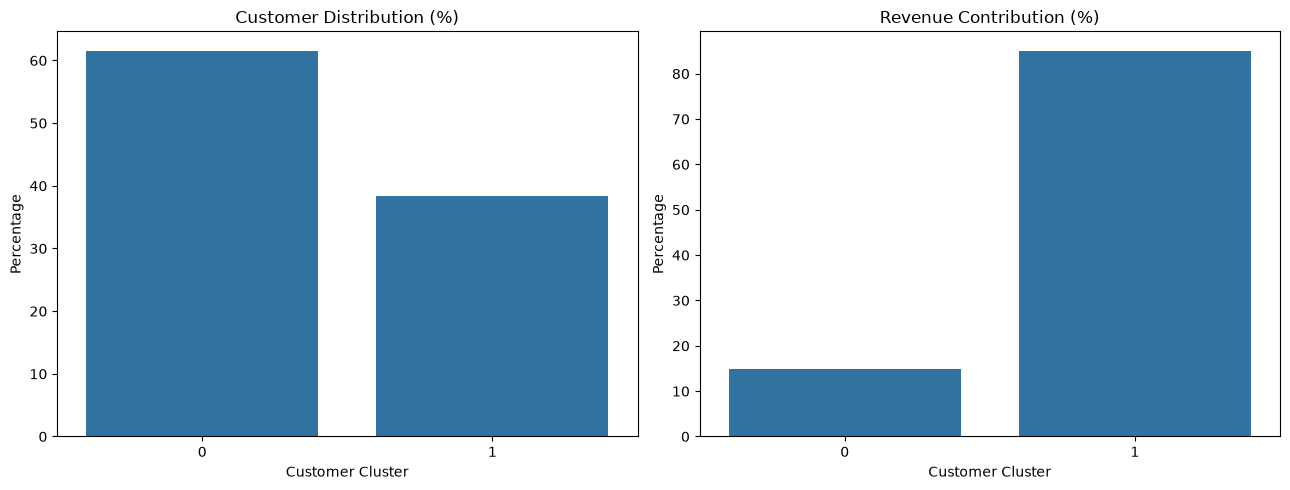

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    x=business_summary.index,
    y=business_summary["Customer_Percentage"],
    ax=axes[0]
)
axes[0].set_title("Customer Distribution (%)")
axes[0].set_xlabel("Customer Cluster")
axes[0].set_ylabel("Percentage")

sns.barplot(
    x=business_summary.index,
    y=business_summary["Revenue_Percentage"],
    ax=axes[1]
)
axes[1].set_title("Revenue Contribution (%)")
axes[1].set_xlabel("Customer Cluster")
axes[1].set_ylabel("Percentage")

plt.tight_layout()
plt.savefig("../outputs/cluster_business_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [18]:
rfm.to_csv(
    "../outputs/customer_segments.csv",
    index=True
)

print("Customer segmentation results saved successfully!")

Customer segmentation results saved successfully!


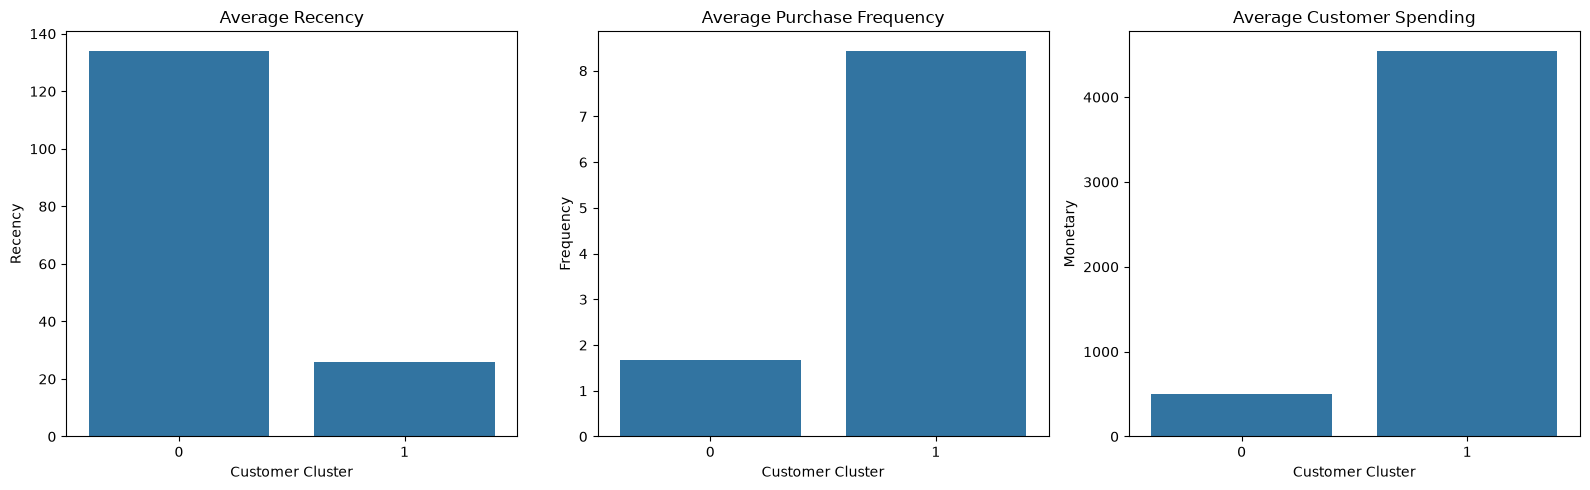

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ["Recency", "Frequency", "Monetary"]
titles = [
    "Average Recency",
    "Average Purchase Frequency",
    "Average Customer Spending"
]

for i, metric in enumerate(metrics):
    sns.barplot(
        x=rfm["Cluster"],
        y=rfm[metric],
        ax=axes[i],
        errorbar=None
    )
    axes[i].set_title(titles[i])
    axes[i].set_xlabel("Customer Cluster")
    axes[i].set_ylabel(metric)

plt.tight_layout()

plt.savefig(
    "../outputs/cluster_rfm_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
business_summary.to_csv(
    "../outputs/cluster_summary.csv"
)

print("Cluster summary saved successfully!")

Cluster summary saved successfully!
